# **Image Classification Cat, Dog, and Other Model Deployment**

# **Nama : Doni Firmansyah**

In [ ]:
# @markdown **Import Library**

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.preprocessing.image import ImageDataGenerator
from keras.preprocessing import image
import os
from google.colab import files, drive
import pathlib

In [ ]:
# @markdown **Collecting Data** :\
# @markdown Dataset yang digunakan adalah dari https://www.kaggle.com/datasets/dhondoi/cat-dog-other

# !mkdir ~/.kaggle
# !cp kaggle.json ~/.kaggle/
# !chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d dhondoi/cat-dog-other -p pet_animal --unzip

!unzip saved_cnn_model_h5
# drive.mount('/content/drive')

Archive:  saved_cnn_model_h5.zip
   creating: saved_cnn_model_h5/
  inflating: saved_cnn_model_h5/cat_vs_dog_vs_other.h5  


In [ ]:
# @markdown **Collecting Data** :\
# @markdown Mount Drive and Copy Checkpoint

drive.mount('/content/drive')

!cp /content/drive/MyDrive/machine_learning/cnn/cat_vs_dog_vs_other/checkpoint_model/cat_vs_dog_vs_other.h5 /content

Mounted at /content/drive


In [ ]:
# @markdown **Collecting Data** :\
# @markdown Checking Total Dataset

ANIMAL = []

print("---------------")
print("Before Splitting")

DIR = "pet_animal"
TOTAL_OUTPUT = len(os.listdir(DIR))
totalAll = 0

for labelName in os.listdir(DIR):
  ANIMAL.append(labelName)

  dirLabel = os.path.join(DIR, labelName)
  total = len([name for name in os.listdir(dirLabel) if os.path.isfile(os.path.join(dirLabel, name))])

  print(f"Count Image {labelName} : {total}")

  totalAll+=total

print(f"\nTotal Image : {totalAll}")
print(f"Label Names : {ANIMAL}")
print("---------------")

---------------
Before Splitting
Count Image other : 5000
Count Image dog : 5000
Count Image cat : 5000

Total Image : 15000
Label Names : ['other', 'dog', 'cat']
---------------


In [ ]:
# @markdown **Pre-Processing Data** :\
# @markdown Generate Image Augmentation Train and Validation Dataset

WIDTH = 150
HEIGHT = 150
BATCH_SIZE = 32

trainIDG = ImageDataGenerator(
    rescale=1.0 / 255,
    horizontal_flip=True,
    zoom_range=0.2,
    shear_range=0.2,
    validation_split=0.2
)
validationIDG = ImageDataGenerator(
    rescale=1.0 / 255,
    validation_split=0.2
)

print("After Splitting Using Image Data Generator")
print("\nDataset Train")
trainDataset = trainIDG.flow_from_directory(DIR,
                                            class_mode='categorical',
                                            target_size=(WIDTH, HEIGHT),
                                            subset="training",
                                            batch_size=BATCH_SIZE,
                                            seed=42
                                            )
STEPS_PER_EPOCH = trainDataset.samples//BATCH_SIZE
print(f"Step Per-Epoch : {STEPS_PER_EPOCH}")

print("\nDataset Validation")
validationDataset = validationIDG.flow_from_directory(DIR,
                                                      class_mode='categorical',
                                                      target_size=(WIDTH, HEIGHT),
                                                      subset="validation",
                                                      batch_size=BATCH_SIZE,
                                                      seed=42
                                                      )

print("---------------")

After Splitting Using Image Data Generator

Dataset Train
Found 12000 images belonging to 3 classes.
Step Per-Epoch : 375

Dataset Validation
Found 3000 images belonging to 3 classes.
---------------


In [ ]:
# @markdown **Pre-Processing Data** :\
# @markdown Creating Callback

class CustomCallback(tf.keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):
      if logs.get("accuracy") > 0.92 and logs.get("val_accuracy") > 0.92:
        print(f"Training and Validation on epoch {epoch+1} get minimum accuracy (92%) : Train {logs.get('accuracy'):.2f} Validation {logs.get('val_accuracy'):.2f}")
        self.model.stop_training = True
      # self.model.save("model.h5")

customCallBack = CustomCallback()

PATIENCE = 5
MONITOR = 'val_loss'
earlyStopping = tf.keras.callbacks.EarlyStopping(monitor=MONITOR, patience=PATIENCE, restore_best_weights=True)

FILE_H5_PATH = "saved_cnn_model_h5/cat_vs_dog_vs_other.h5"
MODE = "min"
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    FILE_H5_PATH,
    monitor=MONITOR,
    save_best_only=True,
    mode=MODE
    )

CALLBACK_LIST = [customCallBack,
                 checkpoint
                 ]

In [ ]:
# @markdown **Pre-Processing Data** :\
# @markdown Modelling

try:
  # !cp /content/drive/MyDrive/<destination-folder-name> FILE_H5_PATH
  model = tf.keras.models.load_model(FILE_H5_PATH)
  print("Loaded Model From H5 File")
except Exception as e:
  print(e)
  print("Creating New Model")

  model = tf.keras.models.Sequential([
      tf.keras.layers.Conv2D(32, (3,3), padding="same", activation='relu', input_shape=(WIDTH, HEIGHT, 3)),
      tf.keras.layers.MaxPooling2D(2, 2),
      tf.keras.layers.Dropout(0.5),
      tf.keras.layers.Conv2D(64, (3,3), padding="same", activation='relu'),
      tf.keras.layers.MaxPooling2D(2,2),
      tf.keras.layers.Dropout(0.5),
      tf.keras.layers.Conv2D(128, (3,3), padding="same", activation='relu'),
      tf.keras.layers.MaxPooling2D(2,2),
      tf.keras.layers.Dropout(0.5),
      tf.keras.layers.Conv2D(256, (3,3), padding="same", activation='relu'),
      tf.keras.layers.MaxPooling2D(2,2),
      tf.keras.layers.Dropout(0.5),
      tf.keras.layers.Flatten(),
      tf.keras.layers.Dropout(0.5),
      tf.keras.layers.Dense(256,
                            activation='relu',
                            kernel_regularizer=tf.keras.regularizers.l2(0.0001)
                            ),
      tf.keras.layers.Dropout(0.5),
      tf.keras.layers.Dense(TOTAL_OUTPUT, activation='softmax')
  ])

  LR_RATE = 0.001
  LR_SCHEDULE = tf.keras.optimizers.schedules.InverseTimeDecay(
    LR_RATE,
    decay_steps=STEPS_PER_EPOCH*10,
    decay_rate=1,
    staircase=False)
  model.compile(loss='categorical_crossentropy',
                optimizer=tf.optimizers.Adam(learning_rate=LR_RATE),
                metrics=['accuracy'])

model.summary()

Loaded Model From H5 File
Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_15 (Conv2D)          (None, 150, 150, 32)      896       
                                                                 
 max_pooling2d_15 (MaxPooli  (None, 75, 75, 32)        0         
 ng2D)                                                           
                                                                 
 dropout_23 (Dropout)        (None, 75, 75, 32)        0         
                                                                 
 conv2d_16 (Conv2D)          (None, 75, 75, 64)        18496     
                                                                 
 max_pooling2d_16 (MaxPooli  (None, 37, 37, 64)        0         
 ng2D)                                                           
                                                                 
 dropout_24 (Dropout)       

In [ ]:
# @markdown **Pre-Processing Data** :\
# @markdown Creating Callback with checkpoint

class CustomCallback(tf.keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):
      if logs.get("accuracy") > 0.92 and logs.get("val_accuracy") > 0.92:
        print(f"Training and Validation on epoch {epoch+1} get minimum accuracy (92%) : Train {logs.get('accuracy'):.2f} Validation {logs.get('val_accuracy'):.2f}")
        self.model.stop_training = True
      # self.model.save("model.h5")

customCallBack = CustomCallback()

PATIENCE = 5
MONITOR = 'val_loss'
earlyStopping = tf.keras.callbacks.EarlyStopping(monitor=MONITOR, patience=PATIENCE, restore_best_weights=True)

FILE_H5_PATH = "saved_cnn_model_h5/cp.ckpt"
MODE = "min"
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    FILE_H5_PATH,
    save_weights_only=True,
    monitor=MONITOR,
    save_best_only=True,
    mode=MODE
    )

CALLBACK_LIST = [customCallBack,
                 checkpoint
                 ]

In [ ]:
# @markdown **Pre-Processing Data** :\
# @markdown Modelling with checkpoint


model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(32, (3,3), padding="same", activation='relu', input_shape=(WIDTH, HEIGHT, 3)),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Conv2D(64, (3,3), padding="same", activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Conv2D(128, (3,3), padding="same", activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Conv2D(256, (3,3), padding="same", activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(256,
                          activation='relu',
                          kernel_regularizer=tf.keras.regularizers.l2(0.0001)
                          ),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(TOTAL_OUTPUT, activation='softmax')
])

# if os.path.exists(FILE_H5_PATH):
#   model.load_weights(FILE_H5_PATH)
# else:
#   print('Checkpoint Not Found! Start Train From Beginning')

model.load_weights(FILE_H5_PATH)

LR_RATE = 0.001
LR_SCHEDULE = tf.keras.optimizers.schedules.InverseTimeDecay(
  LR_RATE,
  decay_steps=STEPS_PER_EPOCH*10,
  decay_rate=1,
  staircase=False)
model.compile(loss='categorical_crossentropy',
              optimizer=tf.optimizers.Adam(learning_rate=LR_RATE),
              metrics=['accuracy'])

model.summary()

In [ ]:
# @markdown **Processing Data** :\
# @markdown Fitting

EPOCH = 1000

history = model.fit(trainDataset,
                    epochs=EPOCH,
                    verbose=2,
                    validation_data=validationDataset,
                    callbacks=CALLBACK_LIST
                    )

# model.save(FILE_H5_PATH)
# !cp FILE_H5_PATH /content/drive/MyDrive/<destination-folder-name>

Epoch 1/1000
375/375 - 83s - loss: 0.7774 - accuracy: 0.7107 - val_loss: 0.7660 - val_accuracy: 0.7033 - 83s/epoch - 222ms/step
Epoch 2/1000
375/375 - 81s - loss: 0.7895 - accuracy: 0.7107 - val_loss: 0.9334 - val_accuracy: 0.6210 - 81s/epoch - 216ms/step
Epoch 3/1000
375/375 - 81s - loss: 0.7775 - accuracy: 0.7209 - val_loss: 0.8427 - val_accuracy: 0.6797 - 81s/epoch - 215ms/step
Epoch 4/1000
375/375 - 82s - loss: 0.7866 - accuracy: 0.7197 - val_loss: 0.7647 - val_accuracy: 0.7293 - 82s/epoch - 218ms/step
Epoch 5/1000
375/375 - 80s - loss: 0.7798 - accuracy: 0.7259 - val_loss: 0.7764 - val_accuracy: 0.7040 - 80s/epoch - 215ms/step
Epoch 6/1000
375/375 - 82s - loss: 0.7544 - accuracy: 0.7355 - val_loss: 0.7969 - val_accuracy: 0.7013 - 82s/epoch - 218ms/step
Epoch 7/1000
375/375 - 81s - loss: 0.7616 - accuracy: 0.7333 - val_loss: 0.8073 - val_accuracy: 0.7080 - 81s/epoch - 216ms/step
Epoch 8/1000
375/375 - 81s - loss: 0.7575 - accuracy: 0.7342 - val_loss: 0.8244 - val_accuracy: 0.6817 -

KeyboardInterrupt: 

In [ ]:
# @markdown **Post-Processing Data** :\
# @markdown Copy Checkpoint to Drive

!cp cat_vs_dog_vs_other.h5 /content/drive/MyDrive/machine_learning/cnn/cat_vs_dog_vs_other/checkpoint_model/cat_vs_dog_vs_other.h5

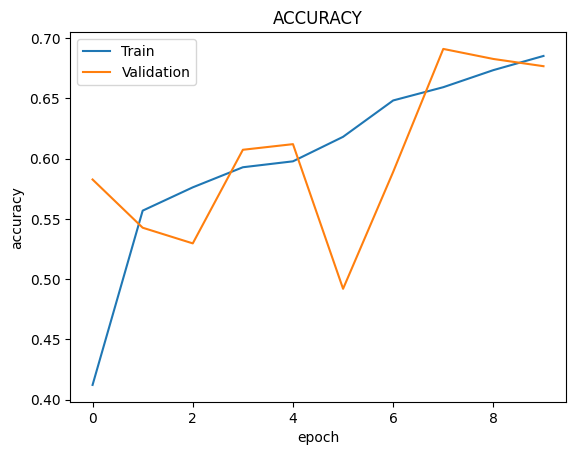

In [ ]:
# @markdown **Post-Processing Data** :\
# @markdown Accuracy Visualization Result

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('ACCURACY')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

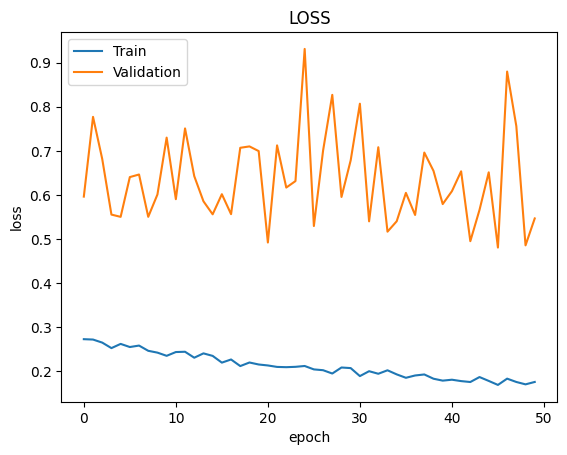

In [ ]:
# @markdown **Post-Processing Data** :\
# @markdown Loss Visualization Result

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('LOSS')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

Saving download (1).jpg to download (1).jpg
Saving download (2).jpg to download (2).jpg
Saving download (4).jpg to download (4).jpg
Saving download (5).jpg to download (5).jpg
Saving download (6).jpg to download (6).jpg
Saving download (7).jpg to download (7).jpg
Saving download (8).jpg to download (8).jpg
Saving download (9).jpg to download (9).jpg
Saving download (10).jpg to download (10).jpg
Saving download (11).jpg to download (11).jpg
Saving download (12).jpg to download (12).jpg
Saving download (13).jpg to download (13).jpg
Saving download (14).jpg to download (14).jpg
Saving download (15).jpg to download (15).jpg
Saving download (16).jpg to download (16).jpg
Saving download (17).jpg to download (17).jpg
Saving download (18).jpg to download (18).jpg
Saving download (19).jpg to download (19).jpg
Saving download (20).jpg to download (20).jpg
Saving download (21).jpg to download (21).jpg
Saving download (22).jpg to download (22).jpg
Saving download (23).jpg to download (23).jpg
Savi

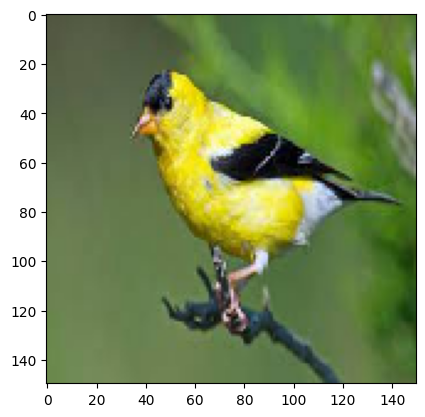

1/1 [==============================] - 0s 426ms/step
Predicted class: other

-------------------
Image 1


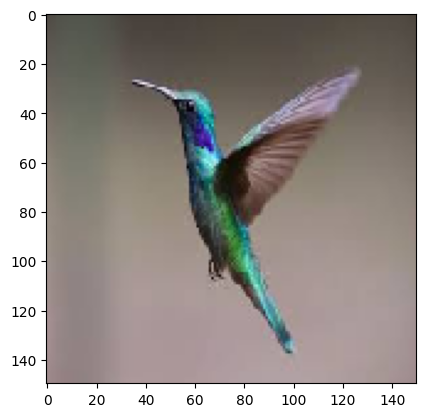

1/1 [==============================] - 0s 27ms/step
Predicted class: other

-------------------
Image 1


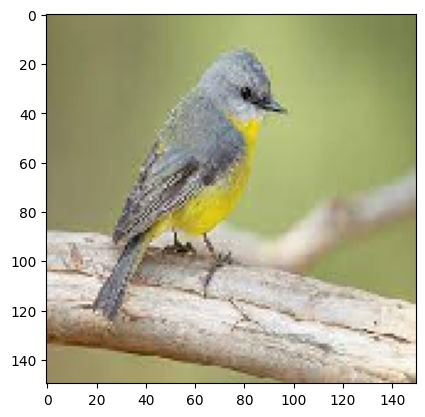

1/1 [==============================] - 0s 32ms/step
Predicted class: other

-------------------
Image 1


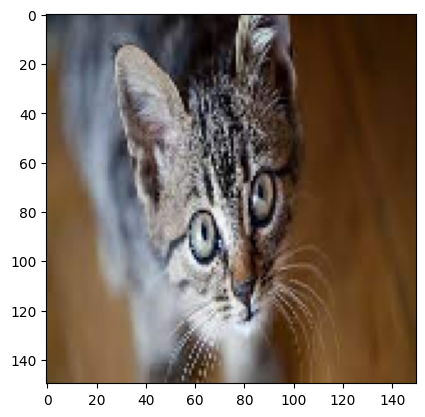

1/1 [==============================] - 0s 17ms/step
Predicted class: dog

-------------------
Image 1


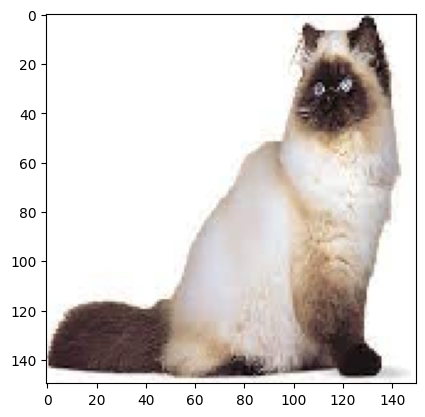

1/1 [==============================] - 0s 19ms/step
Predicted class: dog

-------------------
Image 1


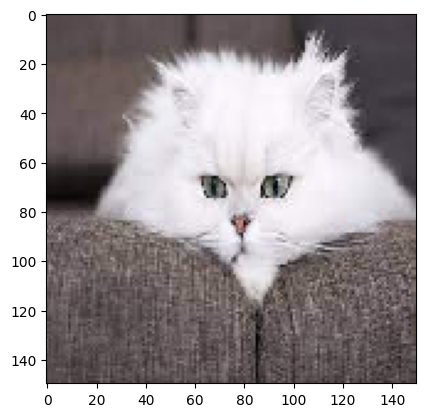

1/1 [==============================] - 0s 17ms/step
Predicted class: other

-------------------
Image 1


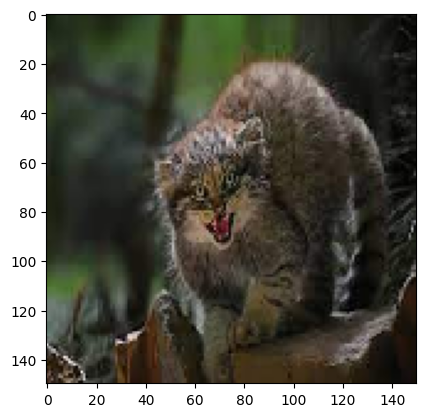

1/1 [==============================] - 0s 18ms/step
Predicted class: cat

-------------------
Image 1


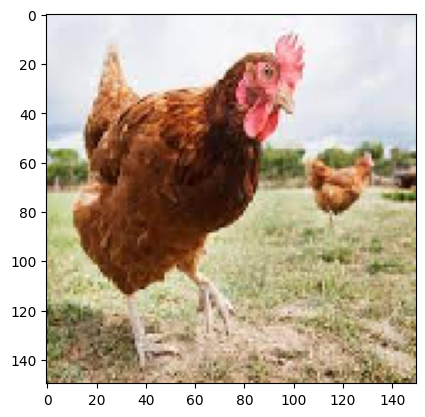

1/1 [==============================] - 0s 21ms/step
Predicted class: other

-------------------
Image 1


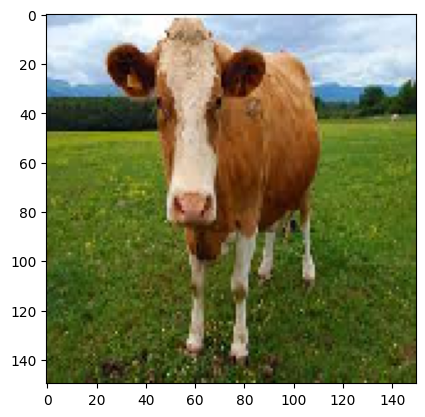

1/1 [==============================] - 0s 22ms/step
Predicted class: cat

-------------------
Image 1


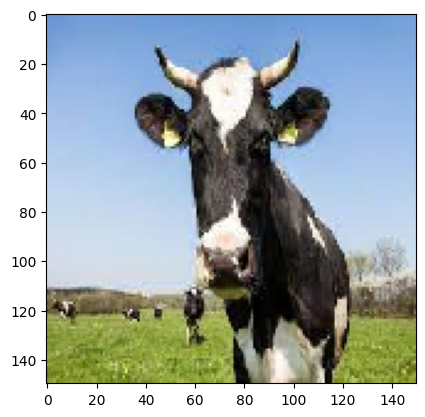

1/1 [==============================] - 0s 20ms/step
Predicted class: cat

-------------------
Image 1


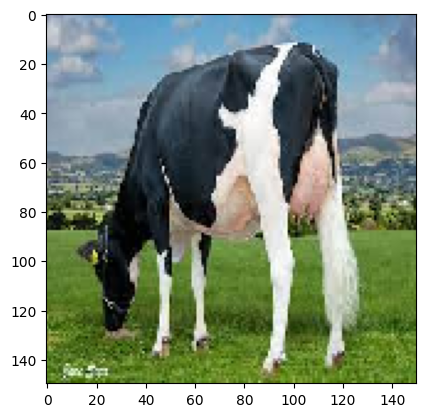

1/1 [==============================] - 0s 22ms/step
Predicted class: cat

-------------------
Image 1


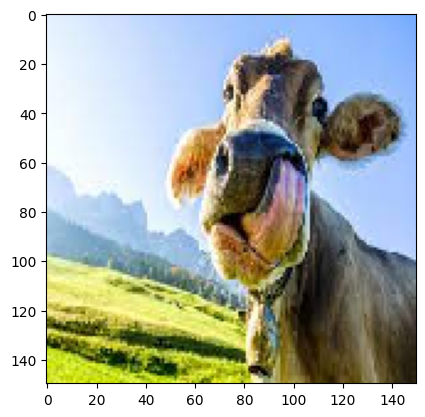

1/1 [==============================] - 0s 23ms/step
Predicted class: cat

-------------------
Image 1


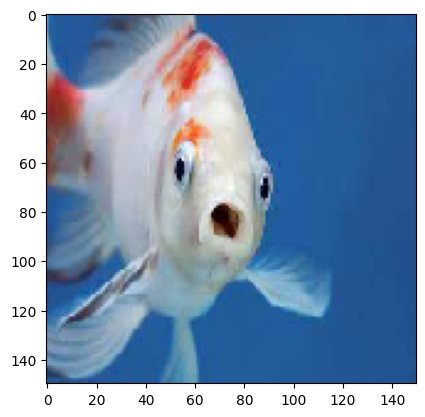

1/1 [==============================] - 0s 19ms/step
Predicted class: cat

-------------------
Image 1


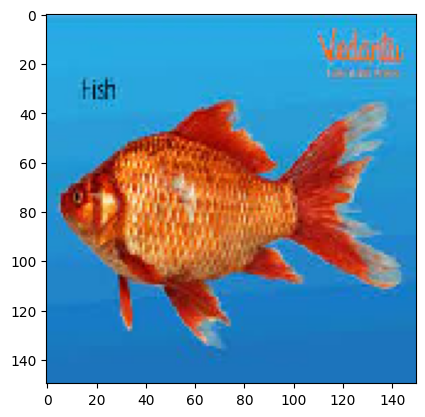

1/1 [==============================] - 0s 18ms/step
Predicted class: cat

-------------------
Image 1


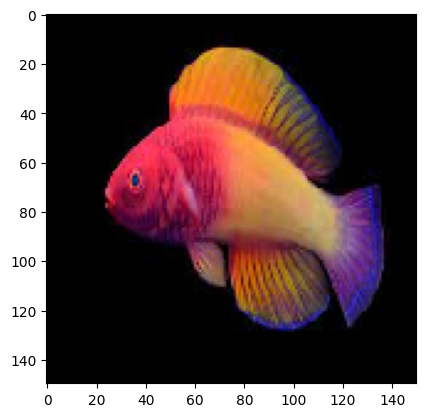

1/1 [==============================] - 0s 18ms/step
Predicted class: other

-------------------
Image 1


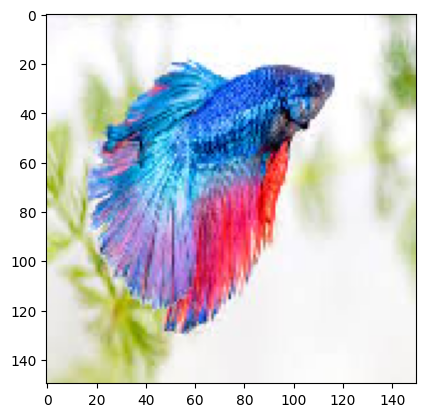

1/1 [==============================] - 0s 25ms/step
Predicted class: other

-------------------
Image 1


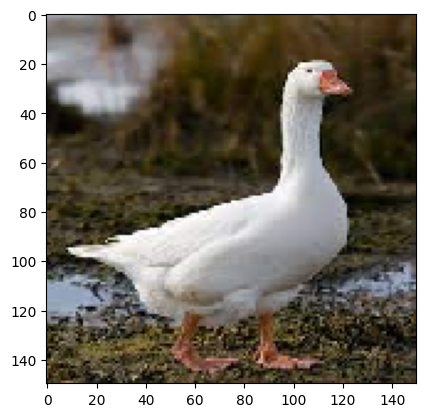

1/1 [==============================] - 0s 35ms/step
Predicted class: cat

-------------------
Image 1


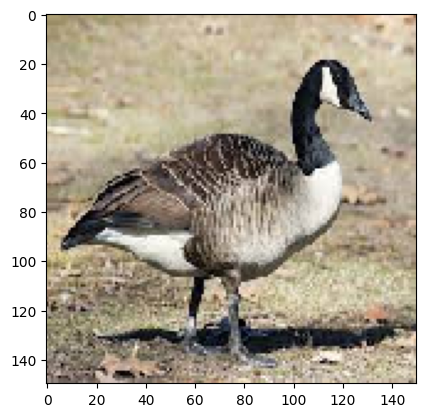

1/1 [==============================] - 0s 25ms/step
Predicted class: other

-------------------
Image 1


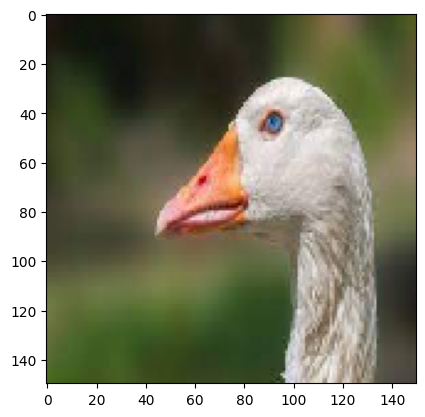

1/1 [==============================] - 0s 24ms/step
Predicted class: dog

-------------------
Image 1


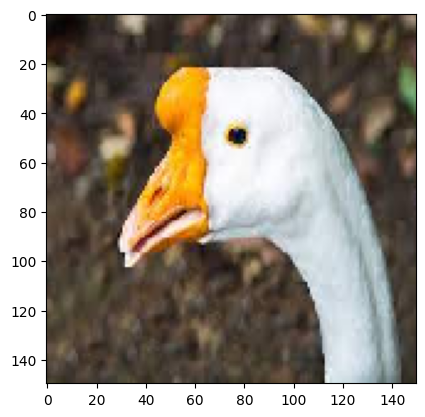

1/1 [==============================] - 0s 31ms/step
Predicted class: other

-------------------
Image 1


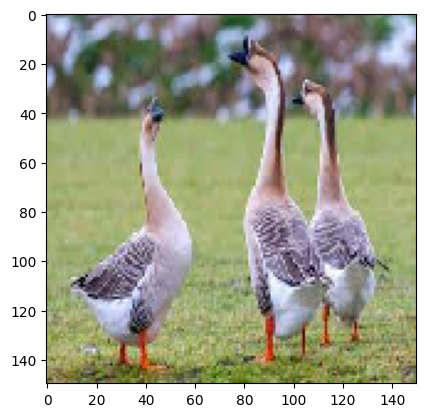

1/1 [==============================] - 0s 25ms/step
Predicted class: other

-------------------
Image 1


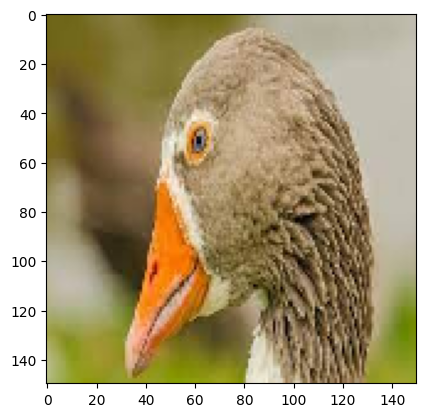

1/1 [==============================] - 0s 25ms/step
Predicted class: dog

-------------------
Image 1


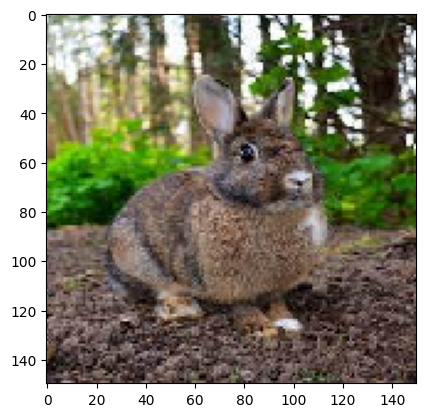

1/1 [==============================] - 0s 36ms/step
Predicted class: cat

-------------------
Image 1


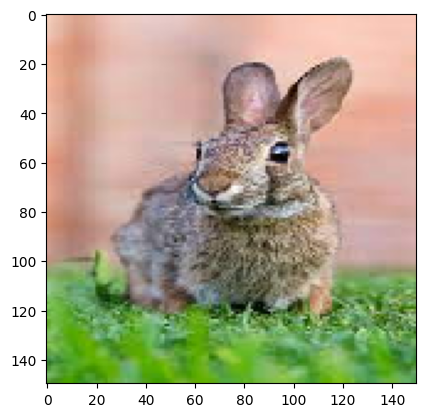

1/1 [==============================] - 0s 26ms/step
Predicted class: dog

-------------------
Image 1


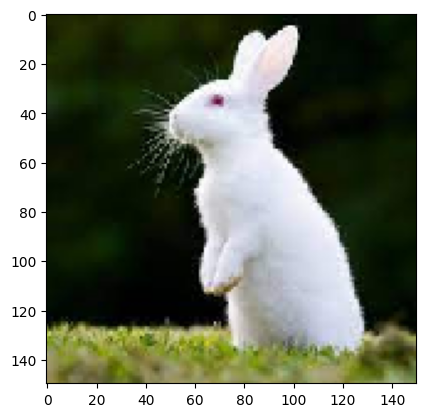

1/1 [==============================] - 0s 24ms/step
Predicted class: cat

-------------------
Image 1


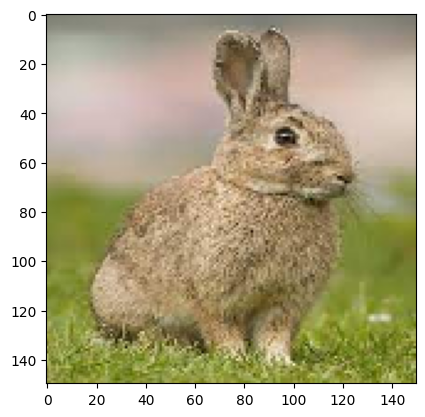

1/1 [==============================] - 0s 24ms/step
Predicted class: other

-------------------
Image 1


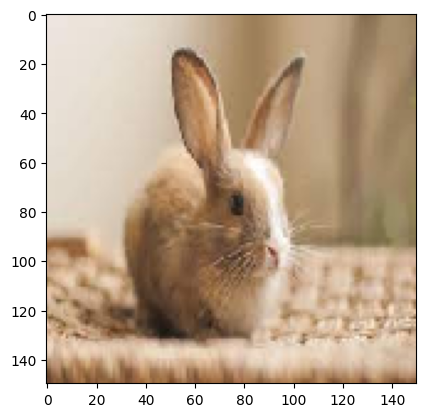

1/1 [==============================] - 0s 24ms/step
Predicted class: other

-------------------
Image 1


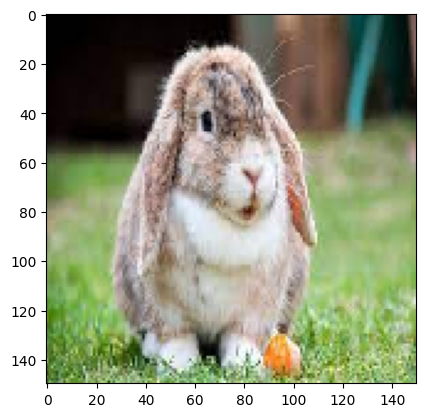

1/1 [==============================] - 0s 25ms/step
Predicted class: dog

-------------------
Image 1


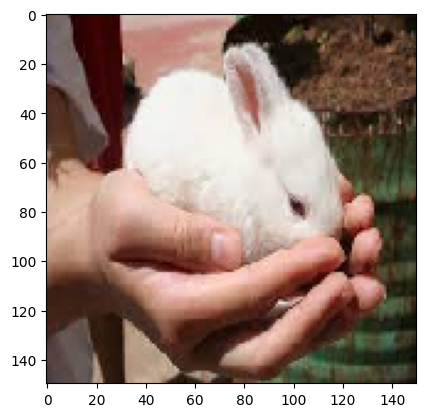

1/1 [==============================] - 0s 32ms/step
Predicted class: dog

-------------------
Image 1


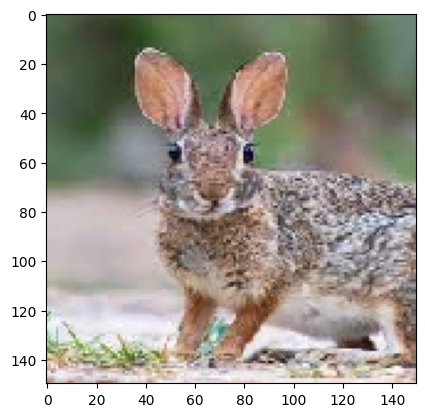

1/1 [==============================] - 0s 25ms/step
Predicted class: dog

-------------------
Image 1


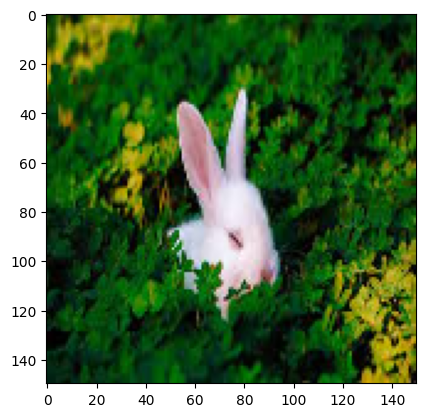

1/1 [==============================] - 0s 25ms/step
Predicted class: cat

-------------------
Image 1


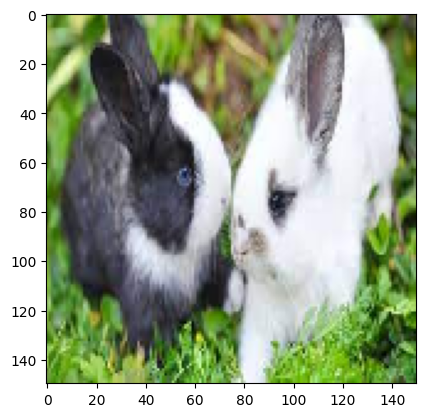

1/1 [==============================] - 0s 27ms/step
Predicted class: dog

-------------------
Image 1


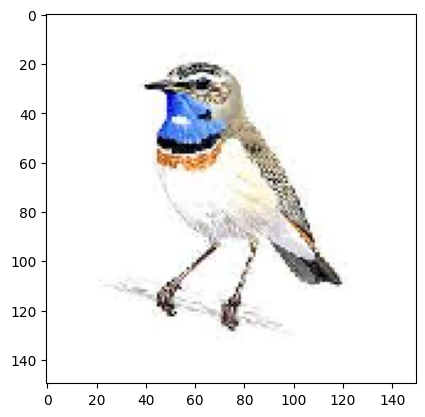

1/1 [==============================] - 0s 31ms/step
Predicted class: dog

-------------------
Image 1


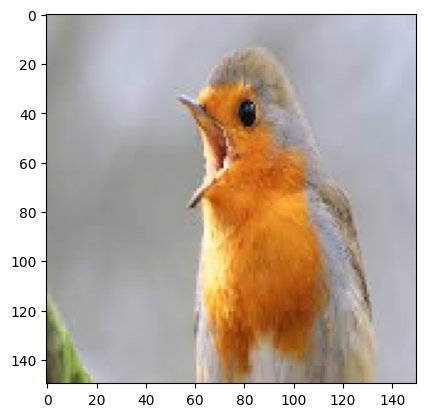

1/1 [==============================] - 0s 29ms/step
Predicted class: other

-------------------
Image 1


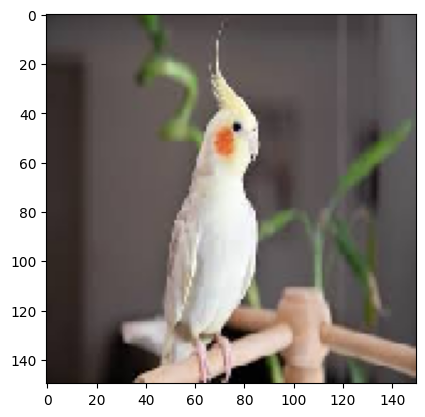

1/1 [==============================] - 0s 31ms/step
Predicted class: other

-------------------
Image 1


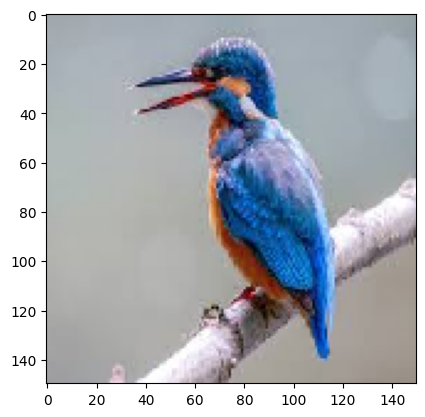

1/1 [==============================] - 0s 27ms/step
Predicted class: other

-------------------
Image 1


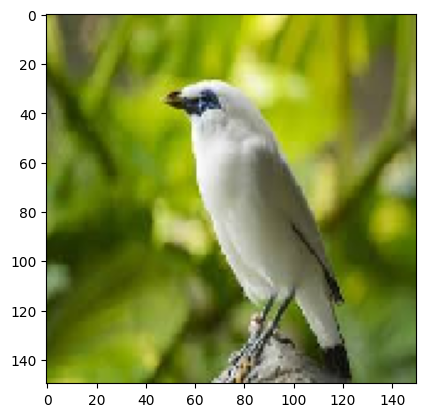

1/1 [==============================] - 0s 24ms/step
Predicted class: dog

-------------------
Image 1


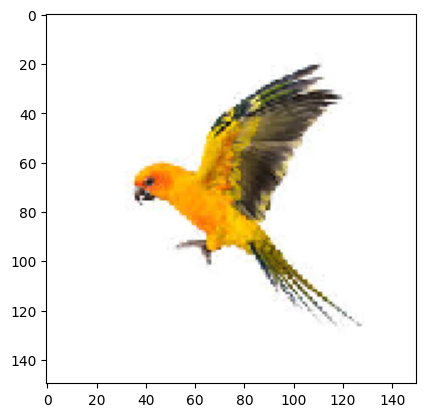

1/1 [==============================] - 0s 25ms/step
Predicted class: other

-------------------
Image 1


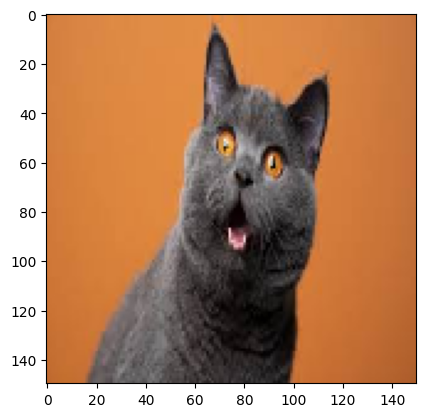

1/1 [==============================] - 0s 27ms/step
Predicted class: dog

-------------------
Image 1


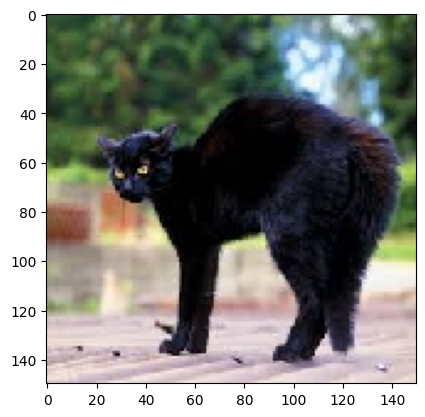

1/1 [==============================] - 0s 37ms/step
Predicted class: other

-------------------
Image 1


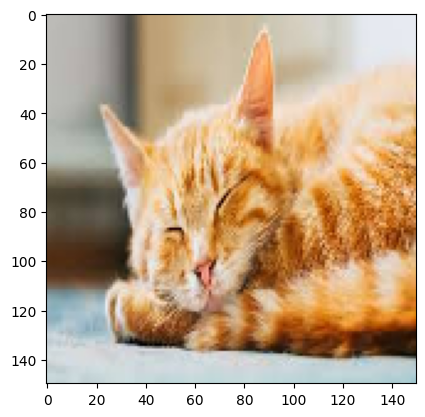

1/1 [==============================] - 0s 26ms/step
Predicted class: other

-------------------
Image 1


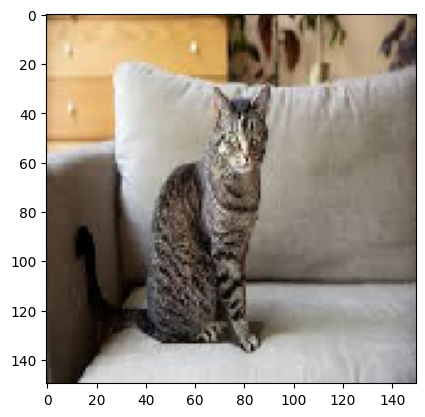

1/1 [==============================] - 0s 38ms/step
Predicted class: dog

-------------------
Image 1


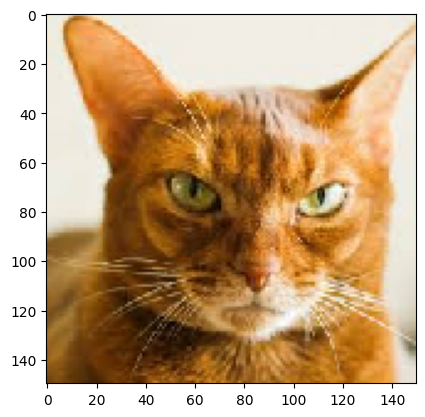

1/1 [==============================] - 0s 24ms/step
Predicted class: dog

-------------------
Image 1


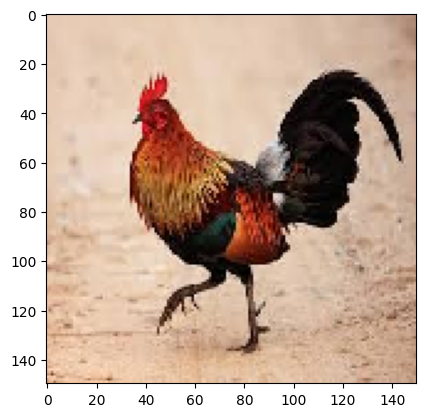

1/1 [==============================] - 0s 24ms/step
Predicted class: cat

-------------------
Image 1


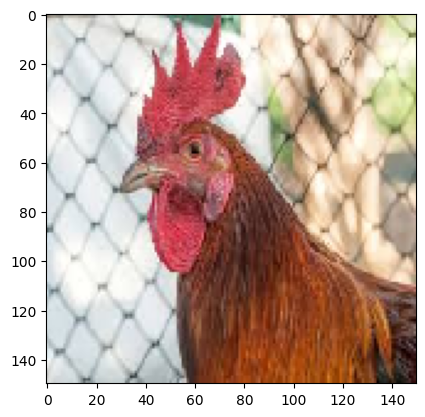

1/1 [==============================] - 0s 24ms/step
Predicted class: other

-------------------
Image 1


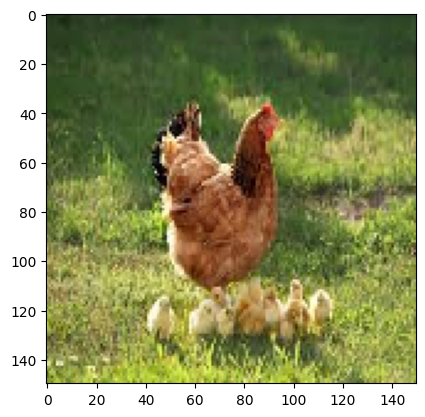

1/1 [==============================] - 0s 26ms/step
Predicted class: cat

-------------------
Image 1


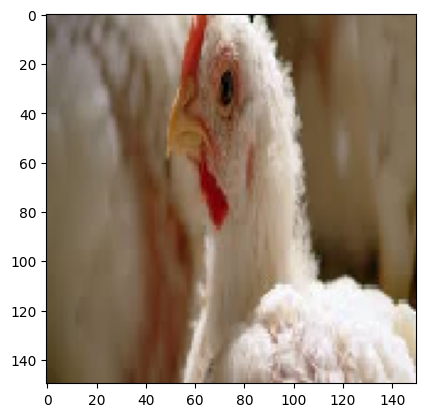

1/1 [==============================] - 0s 28ms/step
Predicted class: other

-------------------
Image 1


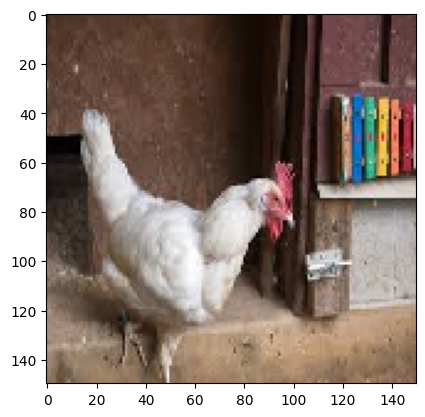

1/1 [==============================] - 0s 26ms/step
Predicted class: dog

-------------------
Image 1


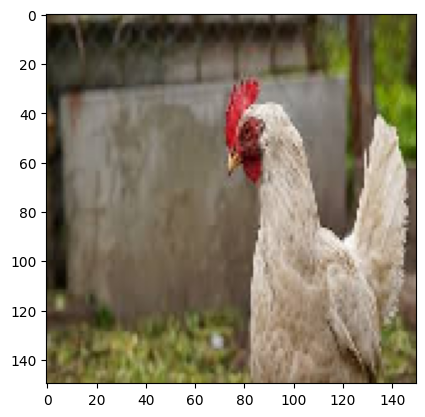

1/1 [==============================] - 0s 24ms/step
Predicted class: other

-------------------
Image 1


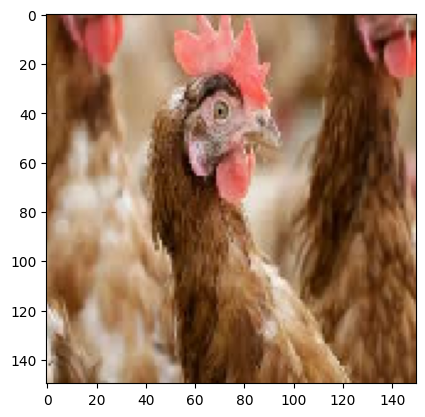

1/1 [==============================] - 0s 27ms/step
Predicted class: dog

-------------------
Image 1


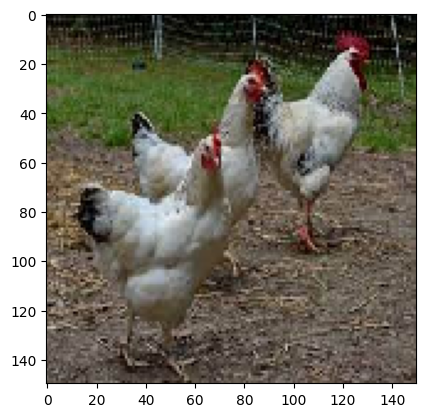

1/1 [==============================] - 0s 25ms/step
Predicted class: dog

-------------------
Image 1


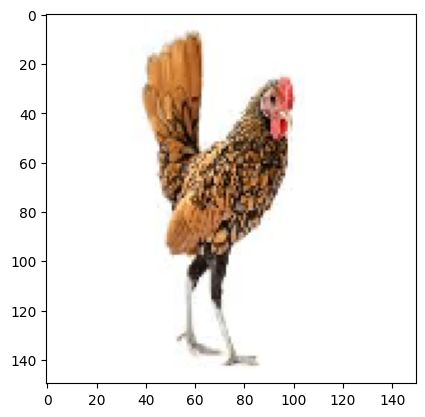

1/1 [==============================] - 0s 28ms/step
Predicted class: dog

-------------------
Image 1


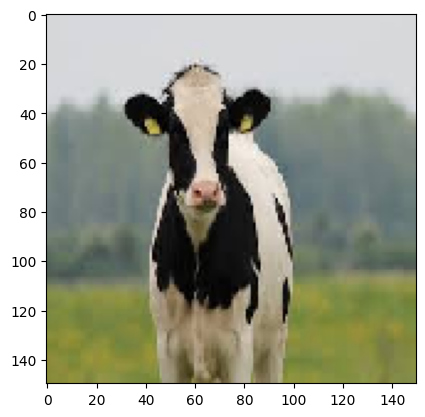

1/1 [==============================] - 0s 24ms/step
Predicted class: cat

-------------------
Image 1


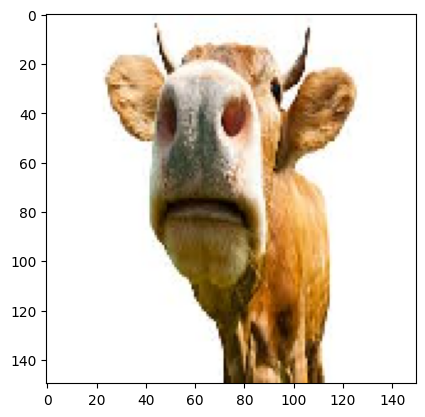

1/1 [==============================] - 0s 26ms/step
Predicted class: other

-------------------
Image 1


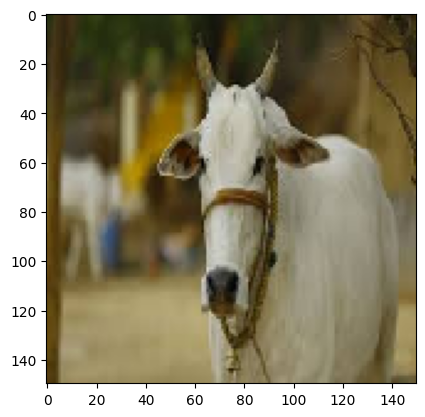

1/1 [==============================] - 0s 34ms/step
Predicted class: cat

-------------------
Image 1


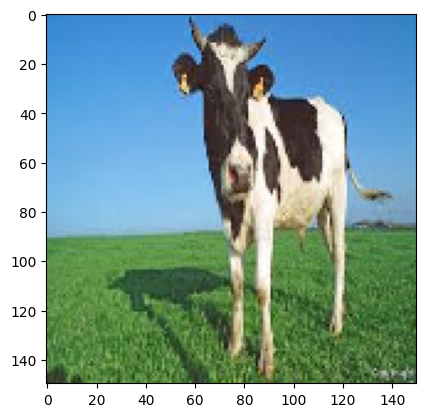

1/1 [==============================] - 0s 26ms/step
Predicted class: cat

-------------------
Image 1


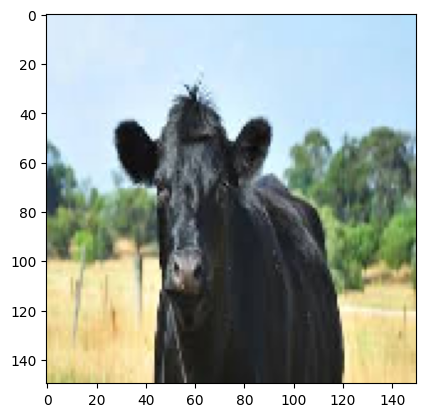

1/1 [==============================] - 0s 27ms/step
Predicted class: other

-------------------
Image 1


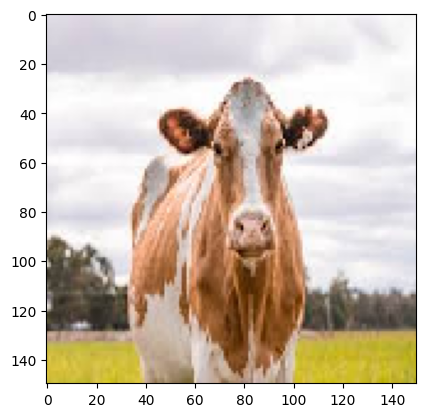

1/1 [==============================] - 0s 24ms/step
Predicted class: other

-------------------
Image 1


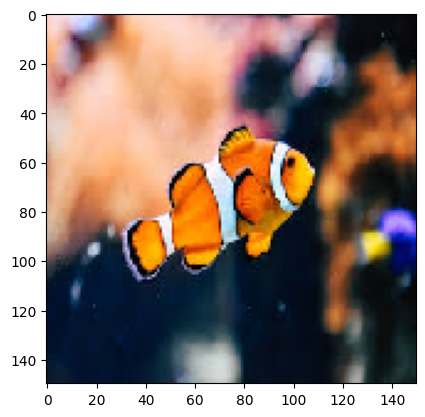

1/1 [==============================] - 0s 25ms/step
Predicted class: other

-------------------
Image 1


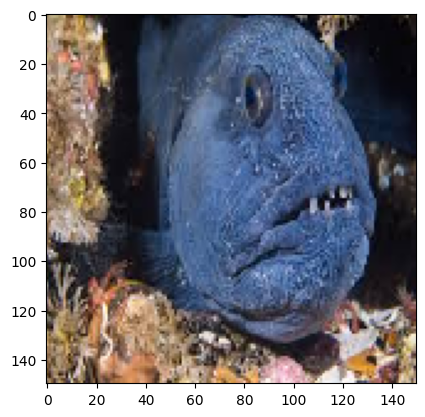

1/1 [==============================] - 0s 24ms/step
Predicted class: other

-------------------
Image 1


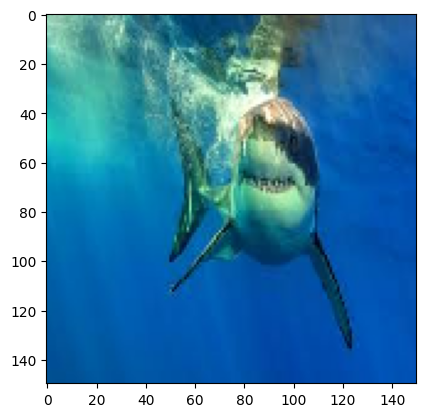

1/1 [==============================] - 0s 25ms/step
Predicted class: other

-------------------
Image 1


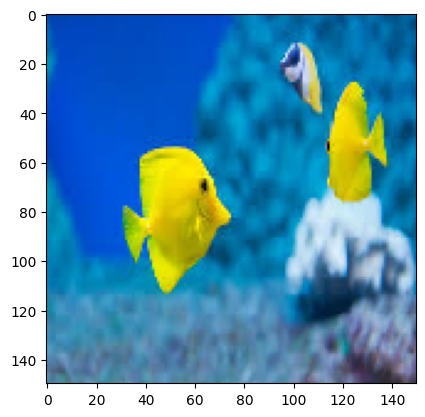

1/1 [==============================] - 0s 30ms/step
Predicted class: other

-------------------
Image 1


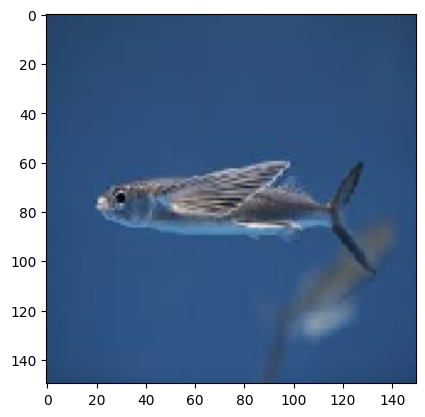

1/1 [==============================] - 0s 47ms/step
Predicted class: dog

-------------------
Image 1


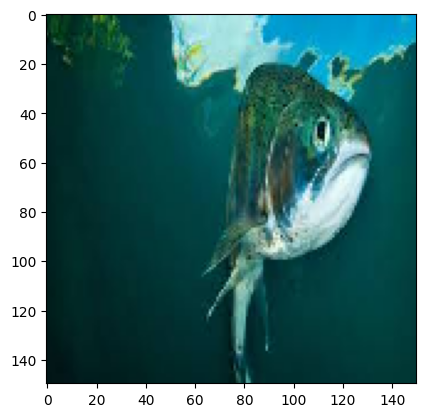

1/1 [==============================] - 0s 41ms/step
Predicted class: dog

-------------------
Image 1


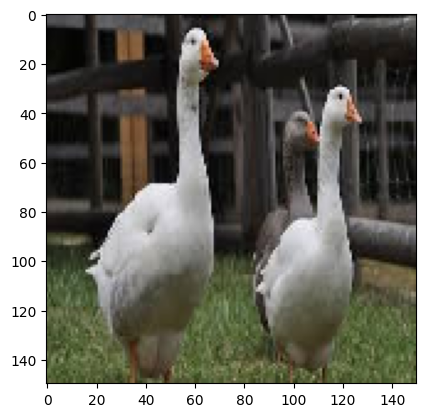

1/1 [==============================] - 0s 30ms/step
Predicted class: cat

-------------------
Image 1


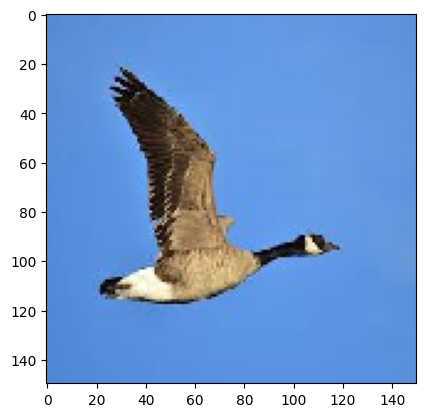

1/1 [==============================] - 0s 45ms/step
Predicted class: cat

-------------------
Image 1


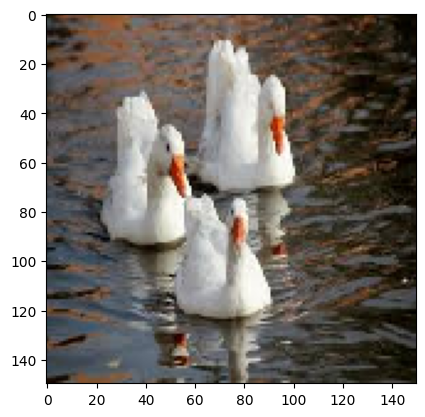

1/1 [==============================] - 0s 25ms/step
Predicted class: other

-------------------
Image 1


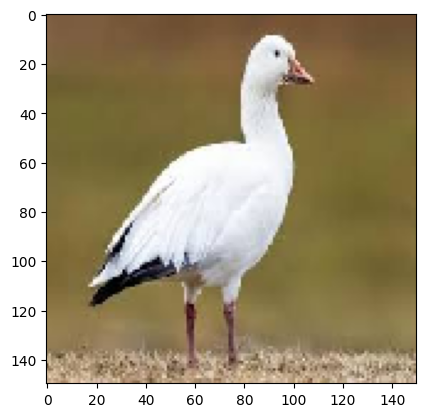

1/1 [==============================] - 0s 28ms/step
Predicted class: dog

-------------------
Image 1


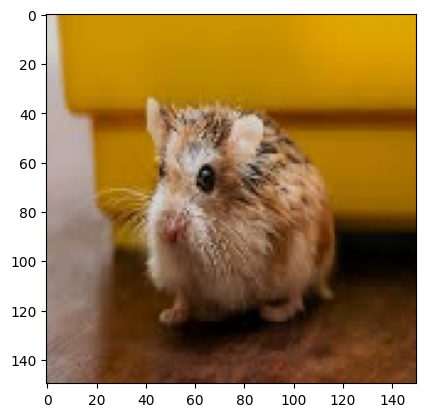

1/1 [==============================] - 0s 28ms/step
Predicted class: dog

-------------------
Image 1


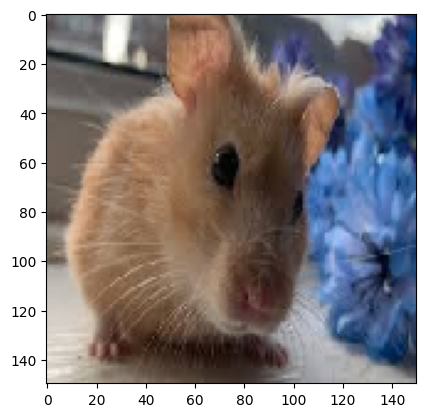

1/1 [==============================] - 0s 24ms/step
Predicted class: other

-------------------
Image 1


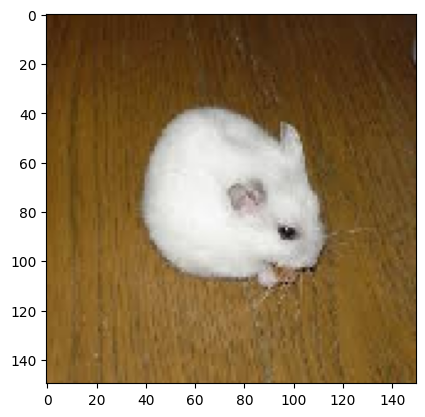

1/1 [==============================] - 0s 28ms/step
Predicted class: dog

-------------------
Image 1


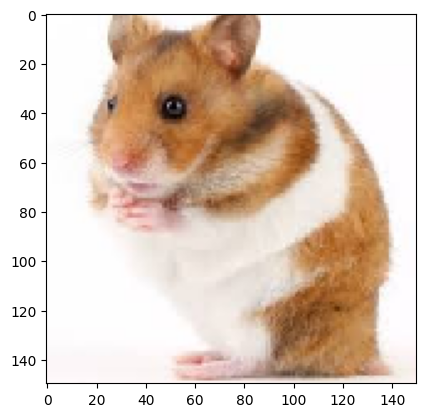

1/1 [==============================] - 0s 26ms/step
Predicted class: other

-------------------
Image 1


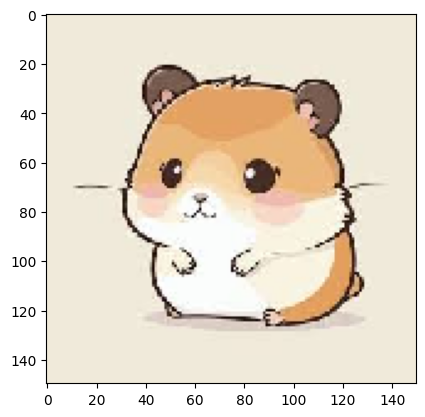

1/1 [==============================] - 0s 26ms/step
Predicted class: other

-------------------
Image 1


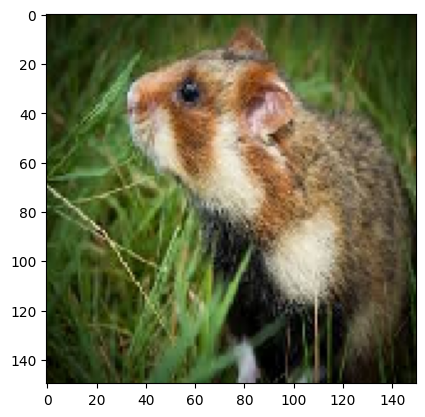

1/1 [==============================] - 0s 28ms/step
Predicted class: other

-------------------
Image 1


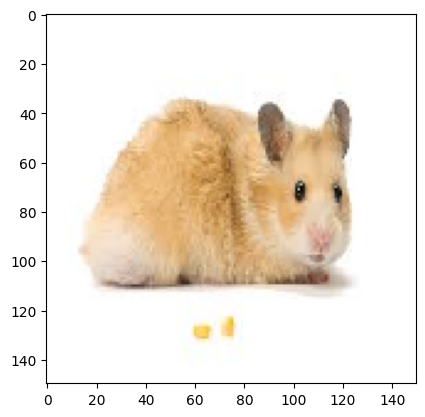

1/1 [==============================] - 0s 25ms/step
Predicted class: other

-------------------
Image 1


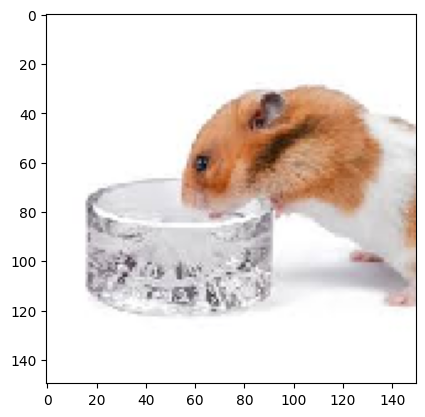

1/1 [==============================] - 0s 25ms/step
Predicted class: other

-------------------
Image 1


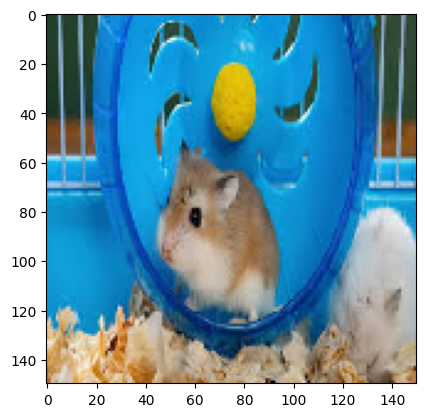

1/1 [==============================] - 0s 24ms/step
Predicted class: dog

-------------------
Image 1


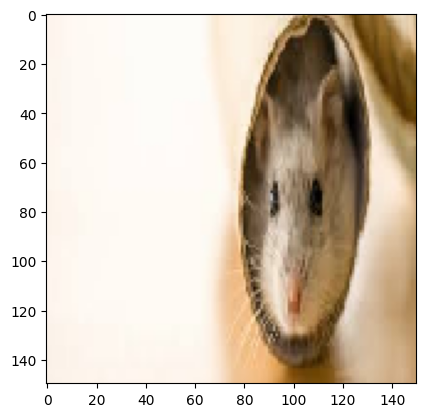

1/1 [==============================] - 0s 27ms/step
Predicted class: other

-------------------
Image 1


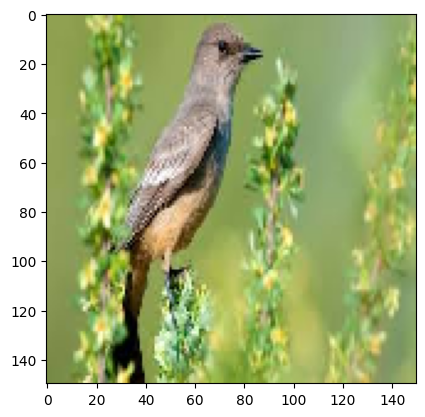

1/1 [==============================] - 0s 24ms/step
Predicted class: cat

-------------------
Image 1


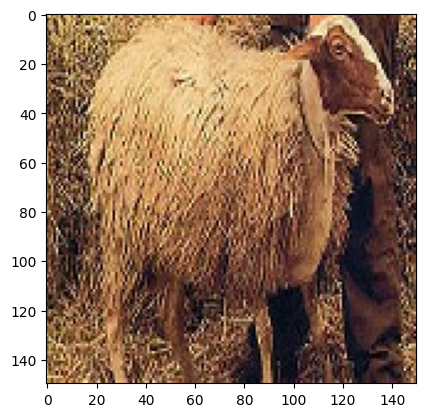

1/1 [==============================] - 0s 25ms/step
Predicted class: dog

-------------------
Image 1


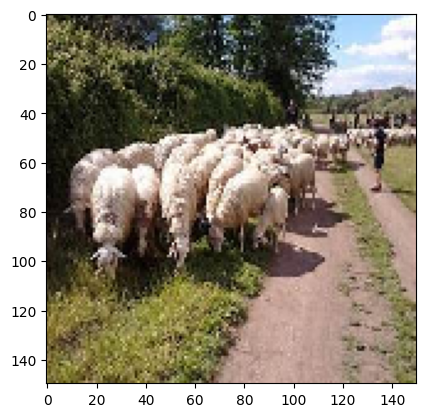

1/1 [==============================] - 0s 25ms/step
Predicted class: cat

-------------------
Image 1


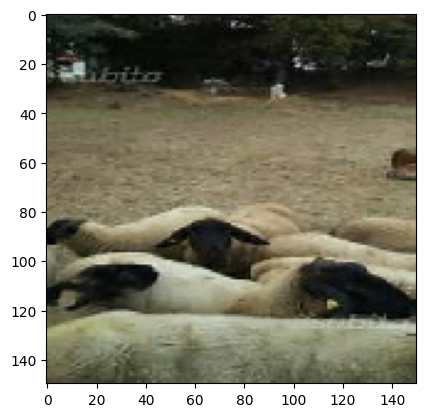

1/1 [==============================] - 0s 27ms/step
Predicted class: dog

-------------------
Image 1


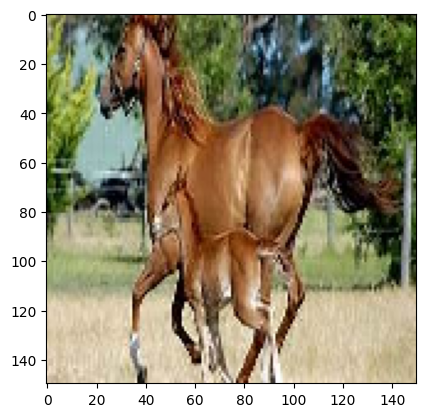

1/1 [==============================] - 0s 28ms/step
Predicted class: cat

-------------------
Image 1


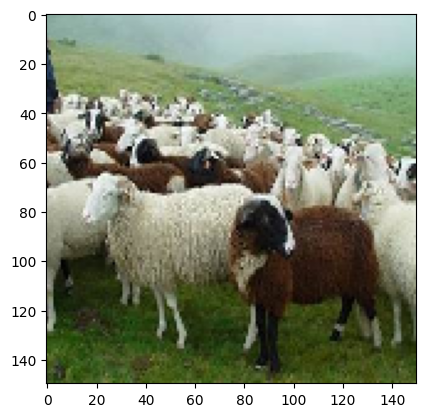

1/1 [==============================] - 0s 26ms/step
Predicted class: cat

-------------------
Image 1


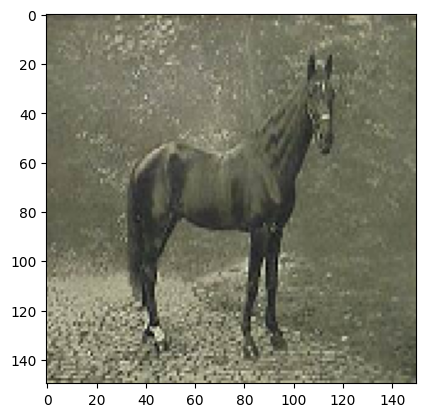

1/1 [==============================] - 0s 25ms/step
Predicted class: other

-------------------
Image 1


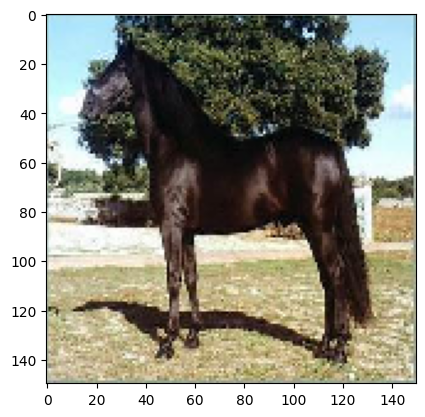

1/1 [==============================] - 0s 24ms/step
Predicted class: cat

-------------------
Image 1


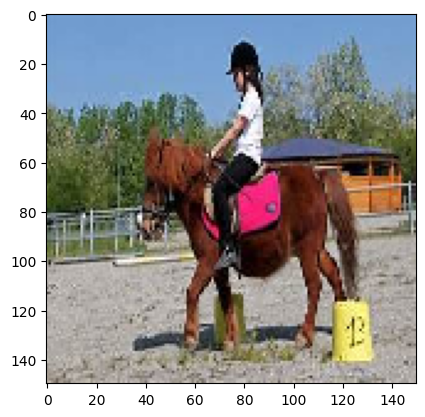

1/1 [==============================] - 0s 24ms/step
Predicted class: cat

-------------------
Image 1


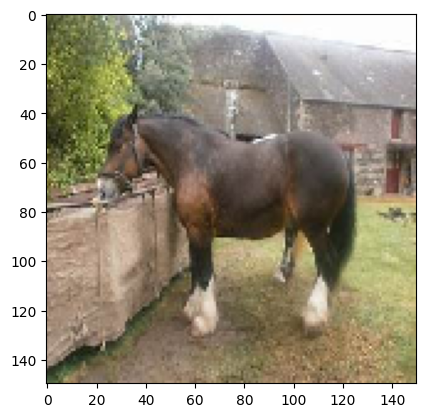

1/1 [==============================] - 0s 25ms/step
Predicted class: other

-------------------
Image 1


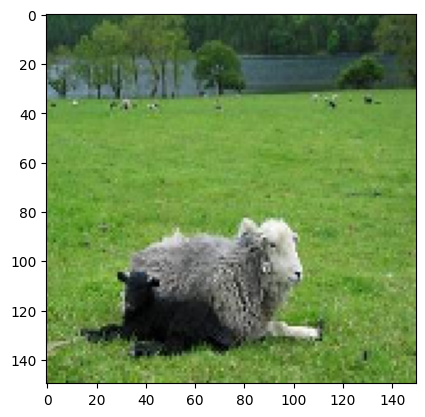

1/1 [==============================] - 0s 37ms/step
Predicted class: cat

-------------------
Image 1


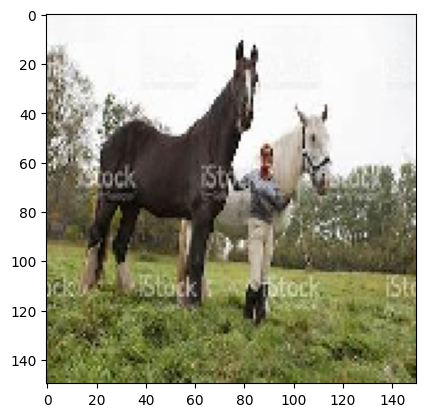

1/1 [==============================] - 0s 29ms/step
Predicted class: cat

-------------------
Image 1


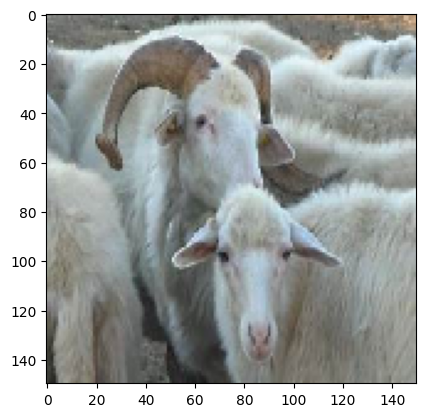

1/1 [==============================] - 0s 24ms/step
Predicted class: dog

-------------------
Image 1


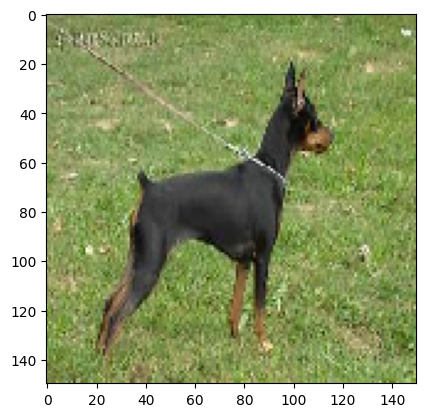

1/1 [==============================] - 0s 36ms/step
Predicted class: cat

-------------------
Image 1


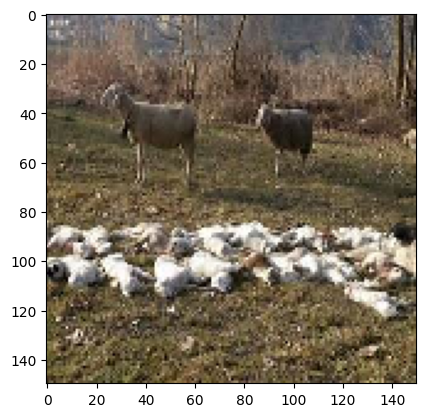

1/1 [==============================] - 0s 38ms/step
Predicted class: cat

-------------------
Image 1


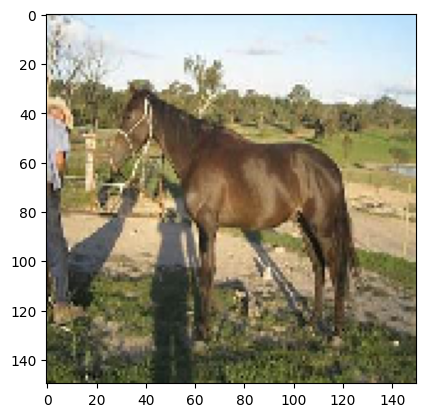

1/1 [==============================] - 0s 42ms/step
Predicted class: other

-------------------
Image 1


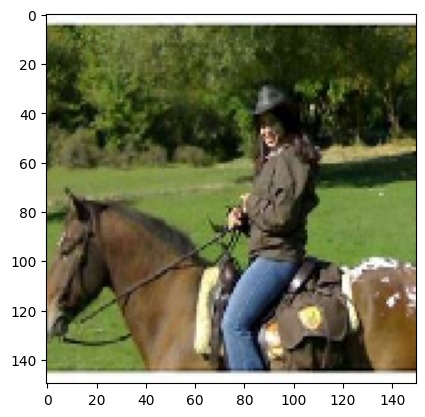

1/1 [==============================] - 0s 24ms/step
Predicted class: cat

-------------------
Image 1


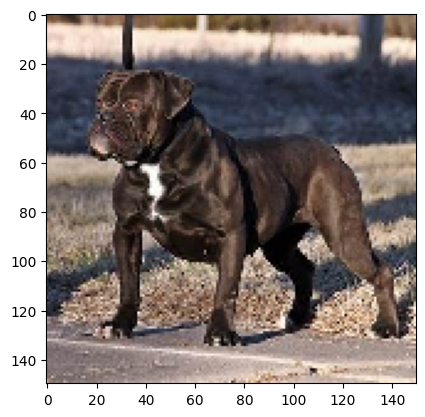

1/1 [==============================] - 0s 25ms/step
Predicted class: cat

-------------------
Image 1


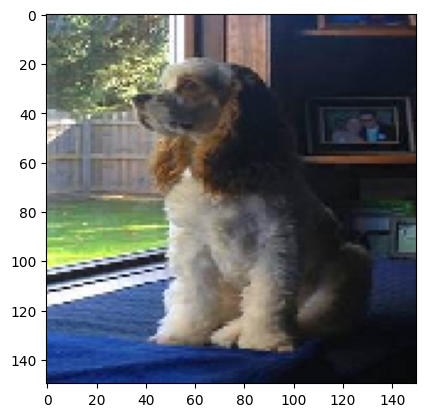

1/1 [==============================] - 0s 24ms/step
Predicted class: dog

-------------------
Image 1


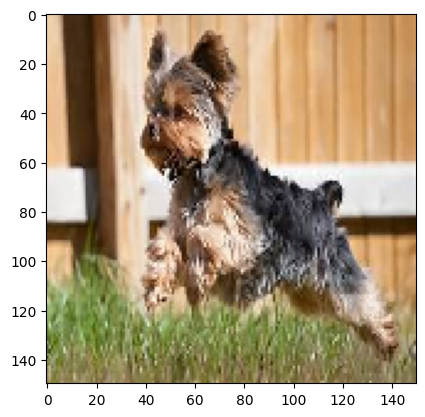

1/1 [==============================] - 0s 26ms/step
Predicted class: dog

-------------------
Image 1


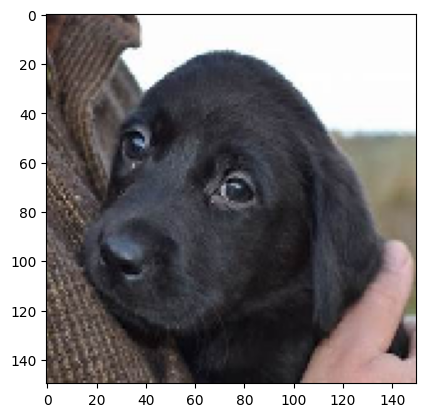

1/1 [==============================] - 0s 26ms/step
Predicted class: dog

-------------------
Image 1


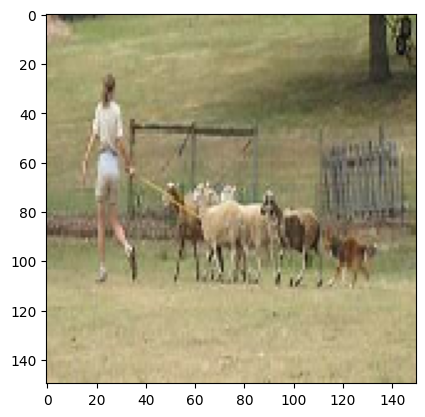

1/1 [==============================] - 0s 25ms/step
Predicted class: dog

-------------------
Image 1


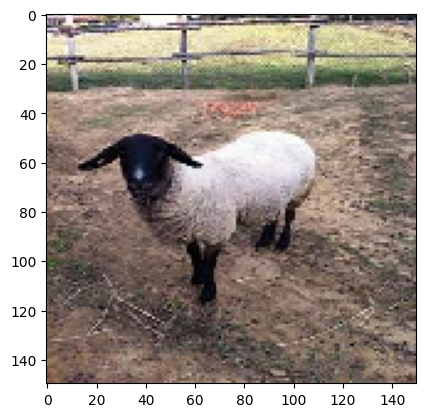

1/1 [==============================] - 0s 29ms/step
Predicted class: other

-------------------
Image 1


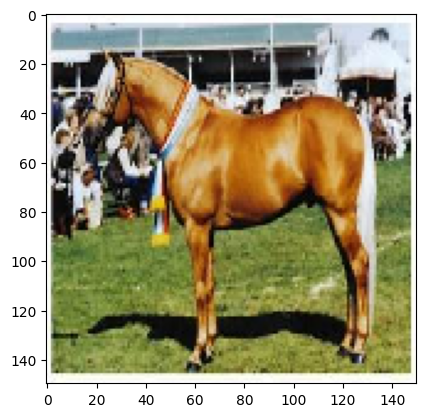

1/1 [==============================] - 0s 38ms/step
Predicted class: cat

-------------------
Image 1


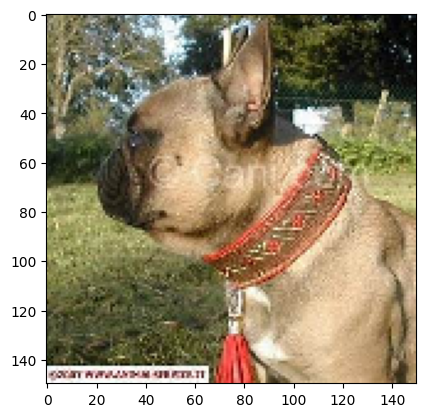

1/1 [==============================] - 0s 28ms/step
Predicted class: other

-------------------
Image 1


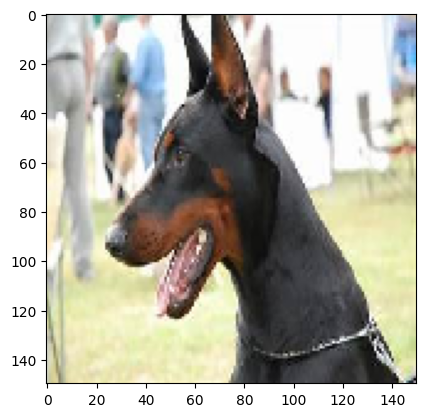

1/1 [==============================] - 0s 26ms/step
Predicted class: other

-------------------
Image 1


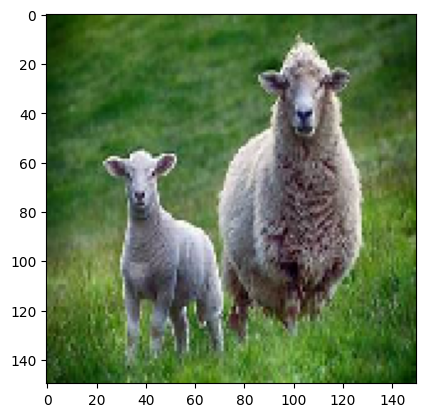

1/1 [==============================] - 0s 25ms/step
Predicted class: dog

-------------------
Image 1


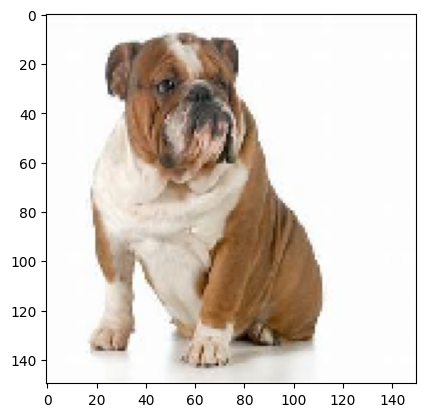

1/1 [==============================] - 0s 29ms/step
Predicted class: dog

-------------------
Image 1


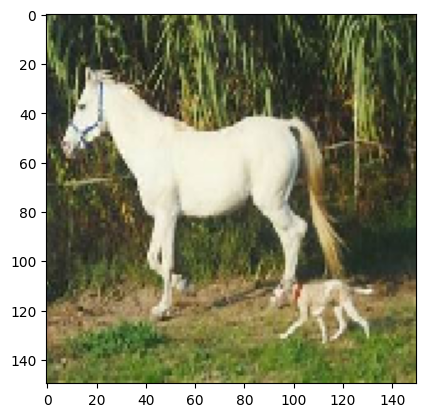

1/1 [==============================] - 0s 37ms/step
Predicted class: other

-------------------
Image 1


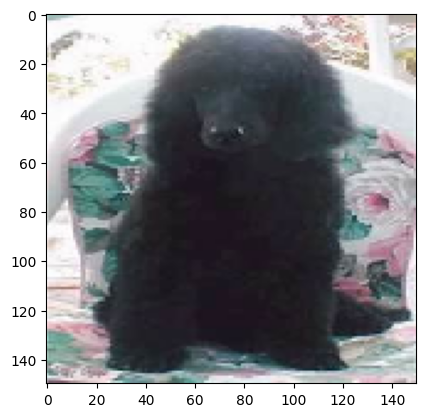

1/1 [==============================] - 0s 24ms/step
Predicted class: other

-------------------
Image 1


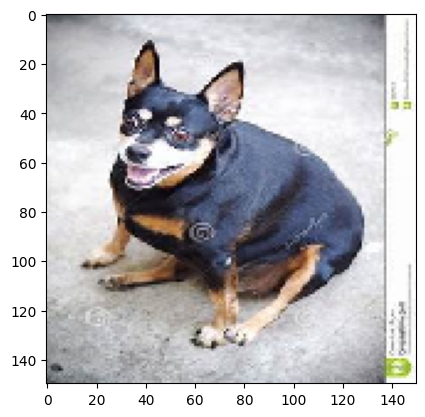

1/1 [==============================] - 0s 25ms/step
Predicted class: other



In [ ]:
# @markdown **Post-Processing Data** :\
# @markdown Predict

# uploaded = files.upload()

# i = 1
# for fn in uploaded.keys():
#   path = fn
#   img = image.load_img(path, target_size =(WIDTH,HEIGHT))
#   plt.imshow(img)
#   print('-------------------')
#   print(f'Image {1}')
#   plt.show()
#   x = image.img_to_array(img)
#   x = np.expand_dims(x, axis=0)

#   images = np.vstack([x])
#   classes = model.predict(images, batch_size=BATCH_SIZE)

#   numbClass = np.argmax(classes, axis=1)
#   print(f'Predicted class: {ANIMAL[numbClass[0]]}\n')


# plt.figure(figsize=(10,10))
# for i in range(25):
#     plt.subplot(5,5,i+1)
#     plt.xticks([])
#     plt.yticks([])
#     plt.grid(False)
#     plt.imshow(train_images[i], cmap=plt.cm.binary)
#     plt.xlabel(class_names[train_labels[i]])
# plt.show()

In [ ]:
# @markdown **Post-Processing Data** :\
# @markdown Saving Model

# exportDir = 'saved_cnn_model/'
# tf.saved_model.save(model, exportDir)


# converter = tf.lite.TFLiteConverter.from_saved_model(exportDir)
# tfLite = converter.convert()


# tfLiteFile = pathlib.Path('cat_vs_dog_vs_other.tflite')
# tfLiteFile.write_bytes(tfLite)

In [ ]:
# !pip install hyperas
from hyperopt import Trials, STATUS_OK, tpe
from hyperas import optim
from hyperas.distributions import choice, uniform

def model():

    model = tf.keras.models.Sequential()
    model_choice = {{choice(['one', 'two'])}}
    if model_choice == 'one':
        model.add(tf.keras.layers.Conv2D(32, (3,3), padding="same", activation='relu', input_shape=(WIDTH, HEIGHT, 3)))
        model.add(tf.keras.layers.MaxPooling2D(2, 2))
        model.add(tf.keras.layers.Dropout({{uniform(0, 1)}}))
        model.add(tf.keras.layers.Conv2D(64, (3,3), padding="same", activation='relu'))
        model.add(tf.keras.layers.MaxPooling2D(2, 2))
        model.add(tf.keras.layers.Dropout({{uniform(0, 1)}}))
        model.add(tf.keras.layers.Conv2D(128, (3,3), padding="same", activation='relu'))
        model.add(tf.keras.layers.MaxPooling2D(2, 2))
        model.add(tf.keras.layers.Dropout({{uniform(0, 1)}}))

    elif model_choice == 'two':
        model.add(tf.keras.layers.Conv2D(64, (3,3), padding="same", activation='relu', input_shape=(WIDTH, HEIGHT, 3)))
        model.add(tf.keras.layers.MaxPooling2D(2, 2))
        model.add(tf.keras.layers.Dropout({{uniform(0, 1)}}))
        model.add(tf.keras.layers.Conv2D(128, (3,3), padding="same", activation='relu'))
        model.add(tf.keras.layers.MaxPooling2D(2, 2))
        model.add(tf.keras.layers.Dropout({{uniform(0, 1)}}))
        model.add(tf.keras.layers.Conv2D(256, (3,3), padding="same", activation='relu'))
        model.add(tf.keras.layers.MaxPooling2D(2, 2))
        model.add(tf.keras.layers.Dropout({{uniform(0, 1)}}))

    model.add(tf.keras.layers.Flatten())
    model.add(tf.keras.layers.Dense({{choice([128, 256])}}, activation='relu'))
    model.add(tf.keras.layers.Dropout({{uniform(0, 1)}}))
    # choiceval = {{choice(['one', 'two'])}}
    # if choiceval == 'two':
    #     model.add(Dense({{choice([256, 512,1024])}}, activation='relu'))
    #     model.add(BatchNormalization())
    #     model.add(Dropout({{uniform(0, 1)}}))

    model.add(tf.keras.layers.Dense(TOTAL_OUTPUT, activation='softmax'))

    adam = tf.keras.optimizers.Adam(lr=0.001)

    model.compile(loss='categorical_crossentropy', metrics=['accuracy'],
                  optimizer=adam)

    model.fit(trainDataset,
              nb_epoch=50,
              verbose=2,
              validation_data=validationDataset
              )
    score, acc = model.evaluate(validationDataset, verbose=0)
    print('Val accuracy:', acc)
    return {'loss': -acc, 'status': STATUS_OK, 'model': model}

best_run, best_model = optim.minimize(model=model,
                                      data=(trainDataset,validationDataset),
                                      algo=tpe.suggest,
                                      max_evals=30,
                                      trials=Trials(),
                                      notebook_name=DIR)

FileNotFoundError: [Errno 2] No such file or directory: '/content/pet_animal.ipynb'